<a href="https://colab.research.google.com/github/marianbewali-creator/BP_CRMCW1/blob/main/BP_20231678_CRMCW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 1 Data Preparation and Feature Engineering**

In [ ]:
import pandas as pd, numpy as np, yfinance as yf, requests, io, os, time

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/BP_20231678_CRMCW1"
for d in ["data", "outputs", "figures"]:
    os.makedirs(f"{BASE}/{d}", exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**1.1 Ticker selection and data acquisition**

In [ ]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text
sp = pd.read_html(io.StringIO(html))[0]
sp["Symbol"] = sp["Symbol"].str.replace(".", "-", regex=False)
sp.to_csv(f"{BASE}/data/sp500_constituents.csv", index=False)
tickers = sp["Symbol"].tolist()
print(len(tickers)); sp.head()

503


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [ ]:
import platform

retrieved = pd.Timestamp.now().strftime("%d %b %Y %H:%M")

# Record software versions
versions = {
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__
}

# Display retrieval date and software versions
print("Retrieved:", retrieved)
print("Software versions:")
for package, version in versions.items():
    print(f"{package}: {version}")

Retrieved: 23 Nov 2026 12:21
Software versions:
Python: 3.13.18
pandas: 2.2.3
numpy: 2.4.6
yfinance: 0.2.66


In [ ]:
USE_CACHE = False

if USE_CACHE:
    adj   = pd.read_csv(f"{BASE}/data/adj_close_raw.csv", index_col=0, parse_dates=True)
    close = pd.read_csv(f"{BASE}/data/close_raw.csv",     index_col=0, parse_dates=True)
    vol   = pd.read_csv(f"{BASE}/data/volume_raw.csv",    index_col=0, parse_dates=True)
    sp    = pd.read_csv(f"{BASE}/data/sp500_constituents.csv")
    tickers = sp["Symbol"].tolist()
    print("Loaded cached data:", adj.shape)

In [ ]:
parts = []
all_t = tickers + ["^GSPC"]
for i in range(0, len(all_t), 100):
    parts.append(yf.download(all_t[i:i+100], start="2021-01-01", end="2025-01-01",
                             auto_adjust=False, threads=True))
    time.sleep(5)
raw = pd.concat(parts, axis=1)

[*********************100%***********************]  100 of 100 completed
[*********************100%***********************]  100 of 100 completed
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  100 of 100 completed
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  100 of 100 completed
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 173

**1.2 Data validation and alignment**

In [ ]:
def field_validation_report(frame, field_name):
    report = pd.DataFrame({
        "missing_count": frame.isna().sum(),
        "missing_percent": (frame.isna().mean() * 100).round(2),
        "first_valid_date": frame.apply(lambda s: s.first_valid_index()),
        "last_valid_date": frame.apply(lambda s: s.last_valid_index())
    })
    report.insert(0, "field", field_name)
    return report


close_report = field_validation_report(close, "Close")
adj_report = field_validation_report(adj, "Adj Close")
volume_report = field_validation_report(vol, "Volume")

validation_report = pd.concat(
    [close_report, adj_report, volume_report]
)

display(validation_report)

,field,missing_count,missing_percent,first_valid_date,last_valid_date
Ticker,,,,,
A,Close,0,0.0,2021-01-04,2024-12-31
AAPL,Close,0,0.0,2021-01-04,2024-12-31
ABBV,Close,0,0.0,2021-01-04,2024-12-31
ABNB,Close,0,0.0,2021-01-04,2024-12-31
ABT,Close,0,0.0,2021-01-04,2024-12-31
...,...,...,...,...,...
YUM,Volume,0,0.0,2021-01-04,2024-12-31
ZBH,Volume,0,0.0,2021-01-04,2024-12-31
ZBRA,Volume,0,0.0,2021-01-04,2024-12-31


In [ ]:
print("Duplicate dates in Adjusted Close:", adj.index.duplicated().sum())
print("Duplicate dates in Close:", close.index.duplicated().sum())
print("Duplicate dates in Volume:", vol.index.duplicated().sum())

print("Close and Adjusted Close indexes match:", close.index.equals(adj.index))
print("Volume and Adjusted Close indexes match:", vol.index.equals(adj.index))

# Separate individual shares from the S&P 500 benchmark
stocks = adj.drop(columns="^GSPC")

checks = pd.DataFrame(index=stocks.columns)

# History and missing observations
checks["first_date"] = stocks.apply(lambda s: s.first_valid_index())
checks["last_date"] = stocks.apply(lambda s: s.last_valid_index())

checks["missing_close"] = close[stocks.columns].isna().sum()
checks["missing_adj_close"] = adj[stocks.columns].isna().sum()
checks["missing_volume"] = vol[stocks.columns].isna().sum()


checks["nonpositive_close"] = (close[stocks.columns] <= 0).sum()
checks["nonpositive_adj_close"] = (stocks <= 0).sum()
checks["negative_volume"] = (vol[stocks.columns] < 0).sum()
checks["zero_volume_days"] = (vol[stocks.columns] == 0).sum()

checks["volume_missing_with_price"] = (
    vol[stocks.columns].isna() & close[stocks.columns].notna()
).sum()


checks["extreme_daily_moves_40pct"] = (
    stocks.pct_change(fill_method=None).abs() > 0.40
).sum()


adjustment_factor = (
    adj[stocks.columns] / close[stocks.columns].replace(0, np.nan)
)

checks["adjustment_factor_changes"] = (
    adjustment_factor.pct_change(fill_method=None).abs() > 0.005
).sum()

print("\nData validation summary:")
display(checks)

print("\nShares with incomplete histories:",
      ((checks["missing_adj_close"] > 0) |
       (checks["missing_close"] > 0) |
       (checks["missing_volume"] > 0)).sum())

print("Shares with non-positive prices:",
      ((checks["nonpositive_close"] > 0) |
       (checks["nonpositive_adj_close"] > 0)).sum())

print("Shares with negative volume:",
      (checks["negative_volume"] > 0).sum())

print("Shares with zero-volume observations:",
      (checks["zero_volume_days"] > 0).sum())

print("Shares with extreme daily movements:",
      (checks["extreme_daily_moves_40pct"] > 0).sum())

print("Shares with adjustment-factor changes:",
      (checks["adjustment_factor_changes"] > 0).sum())

Duplicate dates in Adjusted Close: 0
Duplicate dates in Close: 0
Duplicate dates in Volume: 0
Close and Adjusted Close indexes match: True
Volume and Adjusted Close indexes match: True

Data validation summary:


,first_date,last_date,missing_close,missing_adj_close,missing_volume,nonpositive_close,nonpositive_adj_close,negative_volume,zero_volume_days,volume_missing_with_price,extreme_daily_moves_40pct,adjustment_factor_changes
Ticker,,,,,,,,,,,,
A,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,0,0
AAPL,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,0,0
ABBV,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,0,16
ABNB,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,0,0
ABT,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...
XYL,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,0,0
YUM,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,0,1
ZBH,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0,0,0



Shares with incomplete histories: 15
Shares with non-positive prices: 0
Shares with negative volume: 0
Shares with zero-volume observations: 2
Shares with extreme daily movements: 7
Shares with adjustment-factor changes: 263


In [ ]:
# Calculate missing Adjusted Close proportions
missing = stocks.isna().mean()

# Identify shares that failed or have more than 10% missing observations
failed = missing[missing == 1].index.tolist()

short = missing[
    (missing > 0.10) & (missing < 1)
].index.tolist()

# Identify shares with invalid price or negative volume observations
invalid_prices = checks.index[
    (checks["nonpositive_close"] > 0) |
    (checks["nonpositive_adj_close"] > 0)
].tolist()

negative_volume = checks.index[
    checks["negative_volume"] > 0
].tolist()

# Retain shares meeting the selection criteria
excluded = set(failed + short + invalid_prices + negative_volume)

keep_stocks = [
    t for t in stocks.columns if t not in excluded
]

keep = keep_stocks + ["^GSPC"]

# Create the selected datasets
adj_c = adj[keep].copy()
close_c = close[keep].copy()
vol_c = vol[keep].copy()

print("Failed completely:", len(failed))
print("More than 10% missing Adjusted Close:", len(short))
print("Excluded due to non-positive prices:", len(invalid_prices))
print("Excluded due to negative volume:", len(negative_volume))
print("Final retained shares:", len(keep_stocks))
print("Missing Adjusted Close observations retained:",
      adj_c[keep_stocks].isna().sum().sum())

Failed completely: 5
More than 10% missing Adjusted Close: 7
Excluded due to non-positive prices: 0
Excluded due to negative volume: 0
Final retained shares: 491
Missing Adjusted Close observations retained: 165


**1.3 Weekly return and weekly beta**

In [ ]:
weekly = adj_c.resample("W-FRI").last()

drop = []
first_day, last_day = adj_c.index[0], adj_c.index[-1]
if first_day > weekly.index[0] - pd.Timedelta(days=4):
    drop.append(weekly.index[0])
if last_day < weekly.index[-1]:
    drop.append(weekly.index[-1])
weekly = weekly.drop(index=drop)
print("Incomplete weeks removed:", [d.date() for d in drop])

wret = weekly.pct_change(fill_method=None).iloc[1:]
mkt = wret["^GSPC"]
wret_stocks = wret.drop(columns="^GSPC")

print("Identical week labels:", wret_stocks.index.equals(mkt.index))
print("Weekly returns:", len(mkt), "| from", mkt.index[0].date(), "to", mkt.index[-1].date())

Incomplete weeks removed: [datetime.date(2025, 1, 3)]
Identical week labels: True
Weekly returns: 207 | from 2021-01-15 to 2024-12-27


In [ ]:
adj_c.to_csv(f"{BASE}/data/adj_close_clean.csv")
close_c.to_csv(f"{BASE}/data/close_clean.csv")
vol_c.to_csv(f"{BASE}/data/volume_clean.csv")
checks.to_csv(f"{BASE}/outputs/validation_checks.csv")
wret.to_csv(f"{BASE}/outputs/weekly_returns.csv")

summary = pd.DataFrame({
    "Step": ["In Wikipedia list", "Failed (no data)", "Dropped (>10% missing)", "Final sample"],
    "Stocks": [len(tickers), len(failed), len(short), len(keep_stocks)]})
summary.to_csv(f"{BASE}/outputs/data_cleaning_summary.csv", index=False)
summary

,Step,Stocks
0,In Wikipedia list,503
1,Failed (no data),5
2,Dropped (>10% missing),7
3,Final sample,491


**1.3.1 Mean weekly return**

In [ ]:
mean_ret = wret_stocks.mean()
print(mean_ret.describe())
print("Highest:", mean_ret.nlargest(5).round(4).to_dict())
print("Lowest:", mean_ret.nsmallest(5).round(4).to_dict())

count    491.000000
mean       0.002895
std        0.002699
min       -0.004468
25%        0.001197
50%        0.002665
75%        0.004234
max        0.017772
dtype: float64
Highest: {'SMCI': 0.0178, 'APP': 0.0144, 'NVDA': 0.0136, 'VRT': 0.0126, 'VST': 0.0114}
Lowest: {'EL': -0.0045, 'BAX': -0.0038, 'DG': -0.0035, 'PYPL': -0.0032, 'ILMN': -0.0031}


**1.3.2 Weekly beta**

In [ ]:
rows = []
for t in wret_stocks.columns:
    d = pd.concat([wret_stocks[t], mkt], axis=1, keys=["stock", "market"]).dropna()
    rows.append({"Ticker": t,
                 "Beta": d["stock"].cov(d["market"]) / d["market"].var(),
                 "AlignedWeeks": len(d)})
beta_df = pd.DataFrame(rows).set_index("Ticker")

print("Check, beta of the S&P 500 with itself:", round(mkt.cov(mkt) / mkt.var(), 4))
print("Total weeks:", len(mkt))
print("Aligned weeks per stock: min", beta_df.AlignedWeeks.min(), "| max", beta_df.AlignedWeeks.max())
print(beta_df.Beta.describe())

returns_beta = pd.DataFrame({"MeanWeeklyReturn": mean_ret}).join(beta_df)
returns_beta.to_csv(f"{BASE}/outputs/return_beta_features.csv")

Check, beta of the S&P 500 with itself: 1.0
Total weeks: 207
Aligned weeks per stock: min 193 | max 207
count    491.000000
mean       0.980713
std        0.420748
min        0.055453
25%        0.668916
50%        0.953176
75%        1.180578
max        3.778560
Name: Beta, dtype: float64


**1.4 Adapted RFM Calculations**

In [ ]:
# RFM observation date and latest 60 trading sessions

S = [c for c in keep if c != "^GSPC"]
Cs, Vs = close_c[S], vol_c[S]

# Final common completed trading date
complete = Cs.notna().all(axis=1) & Vs.notna().all(axis=1)
obs_date = complete[complete].index[-1]

# Trading-session calendar up to observation date
sessions = Vs.loc[:obs_date].index
last60 = sessions[-60:]

print("Observation date:", obs_date.date())
print("60-session window:", last60[0].date(), "to", last60[-1].date())

# Calculate the high-volume threshold separately for each share
high = pd.DataFrame(False, index=sessions, columns=S)
threshold = pd.DataFrame(np.nan, index=sessions, columns=S)

for t in S:
    v = Vs.loc[sessions, t]

    previous_20_mean = v.rolling(
        window=20, min_periods=20
    ).mean().shift(1)

    thr = 2 * previous_20_mean

    threshold[t] = thr
    high[t] = (v > thr).fillna(False)

print("Average high-volume days per share (whole period):",
      high.sum().mean().round(1))

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31
Average high-volume days per share (whole period): 38.0


**1.4.1 Recency**

In [ ]:
def recency(col):
    events = col[col].index
    return (obs_date - events[-1]).days if len(events) else np.nan

R = high.apply(recency)
print(R.describe())
print("Shares with no event (R missing):", R.isna().sum(), R[R.isna()].index.tolist())

count    491.000000
mean      20.433809
std       21.283921
min        4.000000
25%       11.000000
50%       11.000000
75%       16.500000
max      222.000000
dtype: float64
Shares with no event (R missing): 0 []


**1.4.2 Frequency**

In [ ]:
# Count qualifying high-volume days in the latest 60 trading sessions

F = high.loc[last60].sum()

missing_volume_60 = Vs.loc[last60].isna().any()

F[missing_volume_60] = np.nan

print(F.describe())
print("Shares with 0 qualifying events in last 60 sessions:",
      (F == 0).sum())

print("Shares with incomplete volume data in 60-session window:",
      missing_volume_60.sum())

count    491.000000
mean       2.993890
std        1.328634
min        0.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        8.000000
dtype: float64
Shares with 0 qualifying events in last 60 sessions: 10
Shares with incomplete volume data in 60-session window: 0


**1.4.3 Monetary**

In [ ]:
# Calculate daily traded value using Close × Volume
daily_value = (Cs * Vs).loc[last60]

valid_60 = daily_value.notna().all()

M = daily_value.sum(min_count=60)

M[~valid_60] = np.nan

gaps_in_window = daily_value.isna().sum()

print(M.describe())

print("Shares with missing days in the 60-session window:",
      (gaps_in_window > 0).sum())

print("Shares with valid Monetary values:", M.notna().sum())

print("Top 5 by traded value (USD bn):",
      (M.nlargest(5) / 1e9).round(1).to_dict())

count    4.910000e+02
mean     3.973205e+10
std      1.287707e+11
min      1.297483e+09
25%      1.025172e+10
50%      1.670905e+10
75%      3.242874e+10
max      1.847697e+12
dtype: float64
Shares with missing days in the 60-session window: 0
Shares with valid Monetary values: 491
Top 5 by traded value (USD bn): {'TSLA': 1847.7, 'NVDA': 1825.3, 'AAPL': 623.3, 'MSFT': 534.9, 'AMZN': 468.2}


In [ ]:
rfm = pd.DataFrame({"Recency": R, "Frequency": F, "Monetary": M})
features = (returns_beta.join(rfm)
            .join(sp.set_index("Symbol")[["Security", "GICS Sector"]]))
features["ObservationDate"] = obs_date.date()
features.to_csv(f"{BASE}/outputs/feature_table.csv")

rfm_excluded = rfm[rfm.isna().any(axis=1)]
rfm_excluded.to_csv(f"{BASE}/outputs/rfm_excluded.csv")
print("Shares in feature table:", len(features))
print("Excluded from RFM clustering (missing R or M):", len(rfm_excluded), rfm_excluded.index.tolist())

# Spot check one share against the brief's rule
t = "AAPL"
check = pd.DataFrame({"Volume": Vs.loc[last60, t], "Threshold (2x prev 20)": threshold.loc[last60, t],
                      "HighVolume": high.loc[last60, t]})
check[check.HighVolume]

Shares in feature table: 491
Excluded from RFM clustering (missing R or M): 0 []


,Volume,Threshold (2x prev 20),HighVolume
Date,,,
2024-11-25,90152800,87641480.0,True
2024-12-20,147495300,90009210.0,True


**1.5 Metric interpretation and supporting evidence**

In [ ]:
t = "AAPL"

events = high[t][high[t]].index

print(f"--- Worked RFM example: {t} | observation date {obs_date.date()} ---")

# Recency
if len(events) > 0:
    latest_event = events[-1]
    recency_days = (obs_date - latest_event).days

    print(f"\nRecency: latest event = {latest_event.date()}")
    print(f"Recency = {recency_days} calendar days")
else:
    print("\nRecency: No qualifying high-volume event found.")
    print("Recency = missing (NaN), not zero.")

# Frequency
days = high.loc[last60, t]

print("\nFrequency: qualifying high-volume days in the last 60 sessions")

frequency_table = pd.DataFrame({
    "Volume": Vs.loc[last60, t],
    "Threshold (2x previous 20-session mean)": threshold.loc[last60, t],
    "HighVolume": days
})

display(frequency_table[frequency_table["HighVolume"]])

if Vs.loc[last60, t].notna().all():
    print("Frequency =", int(days.sum()))
else:
    print("Frequency cannot be confirmed because of missing volume observations.")

# Monetary
dv = (Cs[t] * Vs[t]).loc[last60]

print("\nMonetary: approximate traded value")

if dv.notna().all():
    d0 = last60[-1]

    print(f"Example daily traded value on {d0.date()}:")
    print(f"${Cs.loc[d0, t]:.2f} × {Vs.loc[d0, t]:,.0f} "
          f"= ${dv.loc[d0]/1e6:,.0f} million")

    print(f"Monetary = sum of 60 daily values = "
          f"${dv.sum()/1e9:,.1f} billion")
else:
    print("Monetary cannot be calculated: missing observations "
          "in the 60-session window.")

--- Worked RFM example: AAPL | observation date 2024-12-31 ---

Recency: latest event = 2024-12-20
Recency = 11 calendar days

Frequency: qualifying high-volume days in the last 60 sessions


,Volume,Threshold (2x previous 20-session mean),HighVolume
Date,,,
2024-11-25,90152800,87641480.0,True
2024-12-20,147495300,90009210.0,True


Frequency = 2

Monetary: approximate traded value
Example daily traded value on 2024-12-31:
$250.42 × 39,480,700 = $9,887 million
Monetary = sum of 60 daily values = $623.3 billion


In [ ]:
feat_cols = ["MeanWeeklyReturn", "Beta", "Recency", "Frequency", "Monetary"]
summary_stats = features[feat_cols].describe().T
summary_stats["median"] = features[feat_cols].median()
summary_stats["skew"] = features[feat_cols].skew()
summary_stats["missing"] = features[feat_cols].isna().sum()
summary_stats.to_csv(f"{BASE}/outputs/feature_summary.csv")
summary_stats.round(4)

,count,mean,std,min,25%,50%,75%,max,median,skew,missing
MeanWeeklyReturn,491.0,2.900000e-03,2.700000e-03,-4.500000e-03,1.200000e-03,2.700000e-03,4.200000e-03,1.780000e-02,2.700000e-03,0.9417,0
Beta,491.0,9.807000e-01,4.207000e-01,5.550000e-02,6.689000e-01,9.532000e-01,1.180600e+00,3.778600e+00,9.532000e-01,1.2571,0
Recency,491.0,2.043380e+01,2.128390e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.650000e+01,2.220000e+02,1.100000e+01,3.6397,0
Frequency,491.0,2.993900e+00,1.328600e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00,3.000000e+00,0.4201,0
Monetary,491.0,3.973205e+10,1.287707e+11,1.297483e+09,1.025172e+10,1.670905e+10,3.242874e+10,1.847697e+12,1.670905e+10,11.6614,0


In [ ]:
rules = pd.DataFrame({"Rule": [
    "Exclude shares with no price data in the study period",
    "Exclude shares missing more than 10% of trading days",
    "Missing prices are never filled; gaps left empty",
    "Weekly prices = last available Adj Close in each Friday-ending week",
    "Incomplete first/final calendar weeks removed (final week ending 2025-01-03)",
    "High-volume day: volume > 2 × mean of the previous 20 sessions, excluding the day itself, per share",
    "Recency in calendar days to observation date 2024-12-31; no event = missing, not 0",
    "Frequency and Monetary use the final 60 trading sessions (2024-10-07 to 2024-12-31)",
    "Monetary = sum of Close × Volume in USD (approximate traded value)"]})
rules.to_csv(f"{BASE}/outputs/validation_rules.csv", index=False)
rules

,Rule
0,Exclude shares with no price data in the study...
1,Exclude shares missing more than 10% of tradin...
2,Missing prices are never filled; gaps left empty
3,Weekly prices = last available Adj Close in ea...
4,Incomplete first/final calendar weeks removed ...
5,High-volume day: volume > 2 × mean of the prev...
6,Recency in calendar days to observation date 2...
7,Frequency and Monetary use the final 60 tradin...
8,Monetary = sum of Close × Volume in USD (appro...


In [ ]:
log = pd.DataFrame(index=sp["Symbol"])
log["Status"] = "Included (all analyses)"
log.loc[log.index.isin(failed), "Status"] = "Excluded: no price data in study period"
log.loc[log.index.isin(short),  "Status"] = "Excluded: more than 10% missing trading days"
log.loc[log.index.isin(rfm_excluded.index), "Status"] = "Included for risk-return only: no high-volume event"
log = log.join(missing.rename("share_of_days_missing"))
log.to_csv(f"{BASE}/outputs/inclusion_exclusion_log.csv")
log["Status"].value_counts()

,count
Status,
Included (all analyses),491
Excluded: more than 10% missing trading days,7
Excluded: no price data in study period,5


In [ ]:
# Threshold alignment: independently check 200 random share-days

rng = np.random.default_rng(42)
ok = []

for _ in range(200):
    t = rng.choice(S)

    v = Vs.loc[sessions, t]
    i = int(rng.integers(20, len(v)))

    # The 20 trading sessions immediately before the tested day
    previous_20 = v.iloc[i-20:i]

    if previous_20.notna().all():
        manual = 2 * previous_20.mean()
        calculated = threshold.loc[v.index[i], t]

        ok.append(np.isclose(manual, calculated))
    else:
        ok.append(pd.isna(threshold.loc[v.index[i], t]))

print("1. Threshold alignment checks passed:", sum(ok), "/", len(ok))

# No-event and same-day handling
print("2. Shares with no event (R missing):", R.isna().sum())

print("   Shares with R = 0:", (R == 0).sum(),
      "| all have an event on the observation date:",
      bool(high.loc[obs_date, R[R == 0].index].all())
      if (R == 0).any() else "n/a")


before = Vs.loc[:last60[0]].iloc[:-1].notna().sum()

print("3. Shares with < 20 valid sessions before the window:",
      (before < 20).sum())

print("   Shares with gaps in the 60-session window:",
      Vs.loc[last60].isna().any().sum())

print("   Zero-volume days inside the window:",
      int((Vs.loc[last60] == 0).sum().sum()))


print("4. NVDA around its split (Close and Volume should both be adjusted):")

print(pd.DataFrame({
    "Close": close.loc["2024-06-05":"2024-06-12", "NVDA"],
    "Volume": vol.loc["2024-06-05":"2024-06-12", "NVDA"],
    "Close × Volume ($bn)": (
        close["NVDA"] * vol["NVDA"]
    ).loc["2024-06-05":"2024-06-12"] / 1e9
}).round(2))


1. Threshold alignment checks passed: 200 / 200
2. Shares with no event (R missing): 0
   Shares with R = 0: 0 | all have an event on the observation date: n/a
3. Shares with < 20 valid sessions before the window: 0
   Shares with gaps in the 60-session window: 0
   Zero-volume days inside the window: 0
4. NVDA around its split (Close and Volume should both be adjusted):
             Close     Volume  Close × Volume ($bn)
Date                                               
2024-06-05  122.44  528402000                 64.70
2024-06-06  121.00  664696000                 80.43
2024-06-07  120.89  412386000                 49.85
2024-06-10  121.79  313434100                 38.17
2024-06-11  120.91  222551200                 26.91
2024-06-12  125.20  299595000                 37.51


In [ ]:
valid = features.dropna(subset=feat_cols).index
features_valid = features.loc[valid]
features_valid.to_csv(f"{BASE}/outputs/feature_table_valid.csv")
print("Common valid share set for ALL clustering:", len(valid))

Common valid share set for ALL clustering: 491


# **Task 2 Stock Segmentation and Sensitivity Analysis**

**2.1 Feature preparation**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.decomposition import PCA

# Use the common valid share set from Task 1
fv = features_valid.copy()

# Separate feature matrices
rr = fv[["MeanWeeklyReturn", "Beta"]].copy()

rfm_m = fv[["Recency", "Frequency", "Monetary"]].copy()

print("Common share set:", len(fv))
print("Risk and Return matrix:", rr.shape)
print("RFM matrix:", rfm_m.shape)

Common share set: 491
Risk and Return matrix: (491, 2)
RFM matrix: (491, 3)


,Skewness,IQR_Outlier_Count
MeanWeeklyReturn,0.942,16.0
Beta,1.257,12.0
Recency,3.640,111.0
Frequency,0.420,2.0
Monetary,11.661,47.0
log1p(Monetary),1.076,14.0


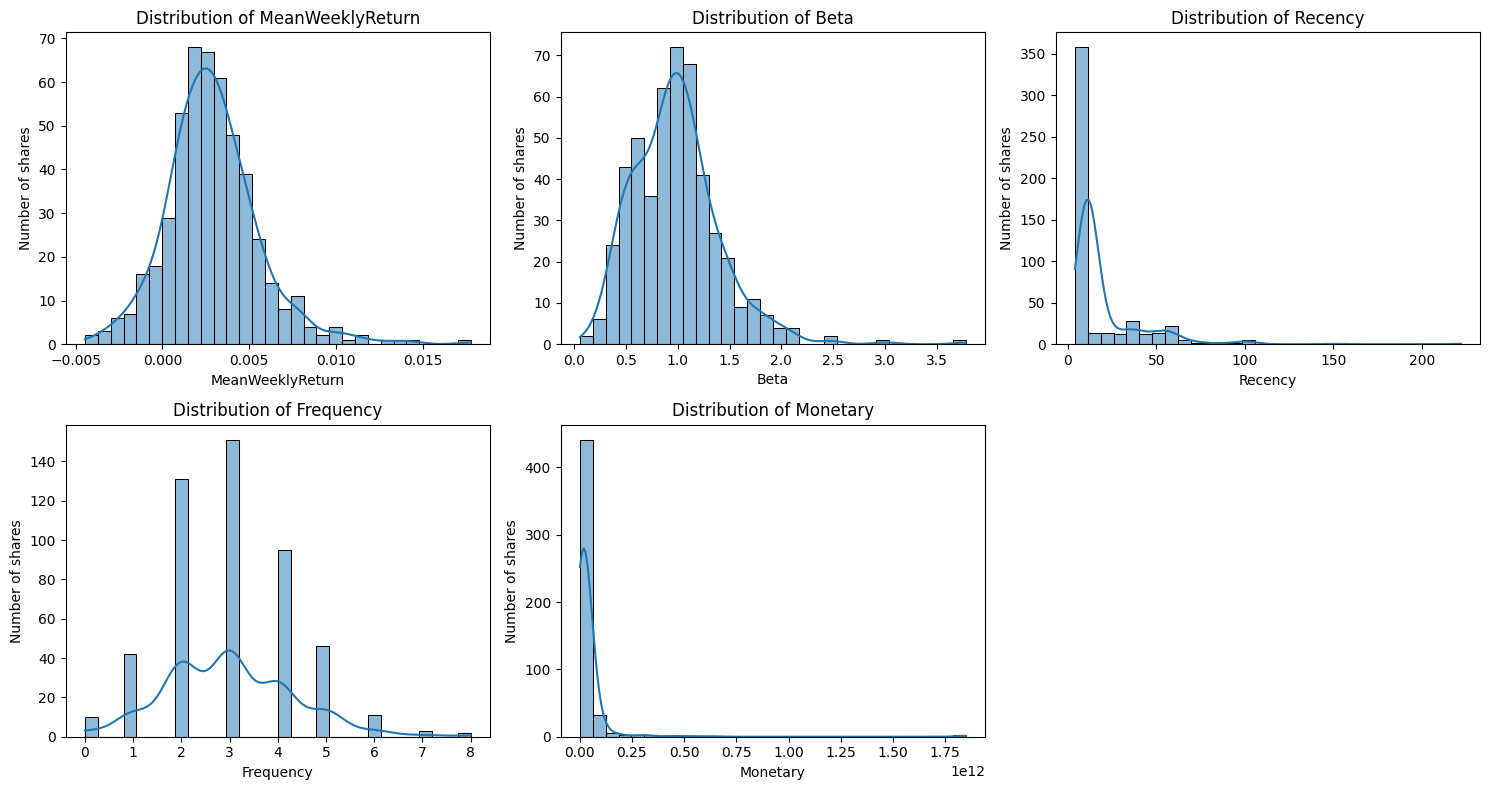

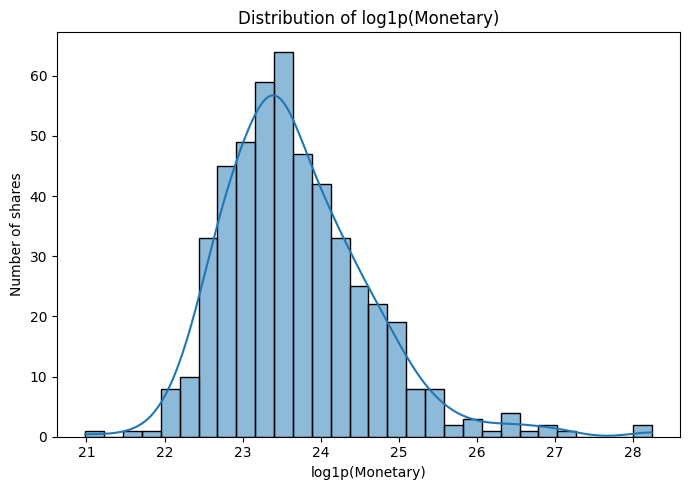

Risk and Return standardised means: [0. 0.]
Risk and Return standardised SDs: [1. 1.]
RFM standardised means: [-0.  0.  0.]
RFM standardised SDs: [1. 1. 1.]


In [ ]:
# Skewness and IQR outlier summary
def iqr_outliers(s):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return int(((s < lower) | (s > upper)).sum())


original_cols = [
    "MeanWeeklyReturn",
    "Beta",
    "Recency",
    "Frequency",
    "Monetary"
]

skew_table = pd.DataFrame({
    "Skewness": fv[original_cols].skew(),
    "IQR_Outlier_Count": fv[original_cols].apply(iqr_outliers)
})

# Add transformed Monetary for comparison
monetary_log = np.log1p(fv["Monetary"])

skew_table.loc["log1p(Monetary)"] = [
    monetary_log.skew(),
    iqr_outliers(monetary_log)
]

display(skew_table.round(3))
skew_table.to_csv(f"{BASE}/outputs/2_1_skewness_outliers.csv")


# Histograms for the five original features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, original_cols):
    sns.histplot(fv[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of shares")

axes[-1].axis("off")

plt.tight_layout()
plt.savefig(f"{BASE}/figures/2_1_original_feature_histograms.png", dpi=300)
plt.show()


# Histogram of transformed Monetary
plt.figure(figsize=(7, 5))
sns.histplot(monetary_log, bins=30, kde=True)
plt.title("Distribution of log1p(Monetary)")
plt.xlabel("log1p(Monetary)")
plt.ylabel("Number of shares")
plt.tight_layout()
plt.savefig(f"{BASE}/figures/2_1_log_monetary_histogram.png", dpi=300)
plt.show()


# Transform Monetary and standardise both matrices
rfm_t = rfm_m.copy()
rfm_t["Monetary"] = np.log1p(rfm_t["Monetary"])

scaler_rr = StandardScaler()
scaler_rfm = StandardScaler()

X_rr = scaler_rr.fit_transform(rr)
X_rfm = scaler_rfm.fit_transform(rfm_t)

print("Risk and Return standardised means:", X_rr.mean(axis=0).round(3))
print("Risk and Return standardised SDs:", X_rr.std(axis=0).round(3))

print("RFM standardised means:", X_rfm.mean(axis=0).round(3))
print("RFM standardised SDs:", X_rfm.std(axis=0).round(3))

**2.2 Agglomerative clustering**

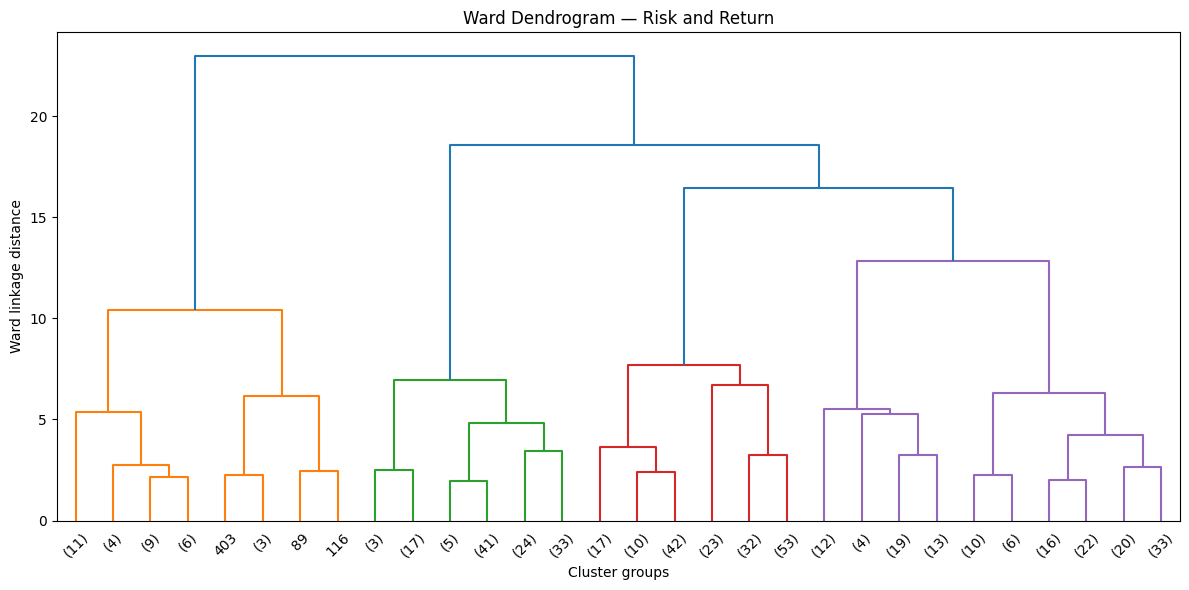

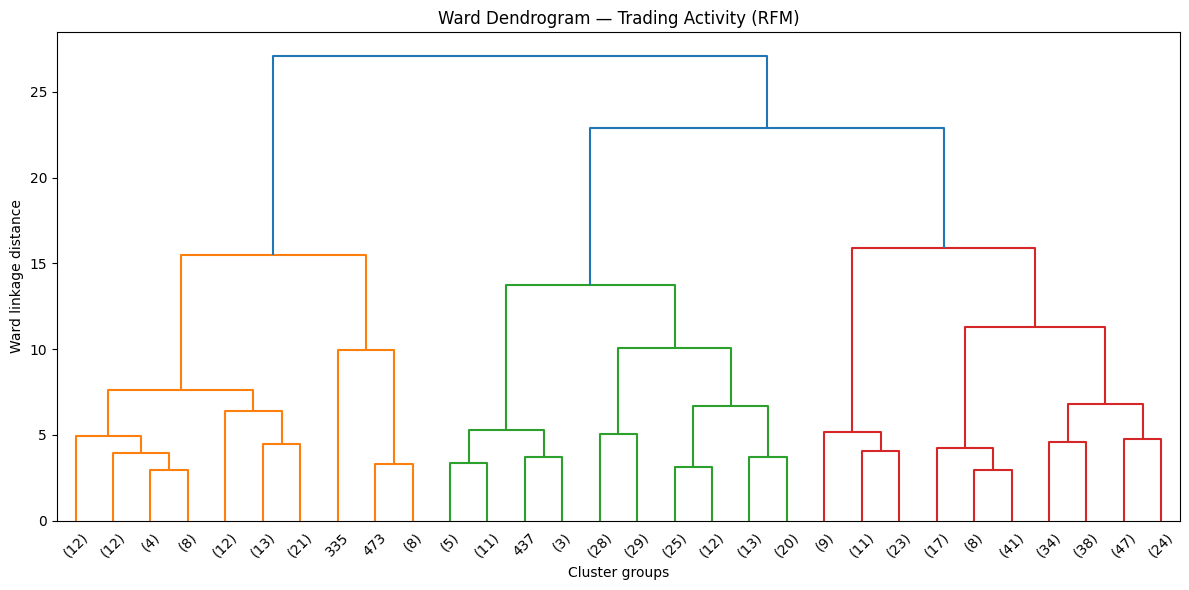

,Clusters,Silhouette Score,Cluster Sizes,Feature Matrix
0,2,0.511,"[455, 36]",Risk and Return
1,3,0.264,"[332, 36, 123]",Risk and Return
2,4,0.296,"[155, 36, 123, 177]",Risk and Return
3,5,0.324,"[36, 177, 123, 107, 48]",Risk and Return
4,6,0.328,"[177, 107, 123, 6, 48, 30]",Risk and Return
5,7,0.295,"[123, 107, 108, 6, 48, 30, 69]",Risk and Return
6,8,0.293,"[108, 107, 30, 6, 48, 103, 69, 20]",Risk and Return


,Clusters,Silhouette Score,Cluster Sizes,Feature Matrix
0,2,0.359,"[399, 92]",RFM
1,3,0.307,"[252, 92, 147]",RFM
2,4,0.293,"[92, 209, 147, 43]",RFM
3,5,0.312,"[147, 209, 10, 43, 82]",RFM
4,6,0.320,"[209, 127, 10, 43, 82, 20]",RFM
5,7,0.298,"[127, 82, 10, 43, 143, 20, 66]",RFM
6,8,0.305,"[10, 82, 70, 43, 143, 20, 66, 57]",RFM


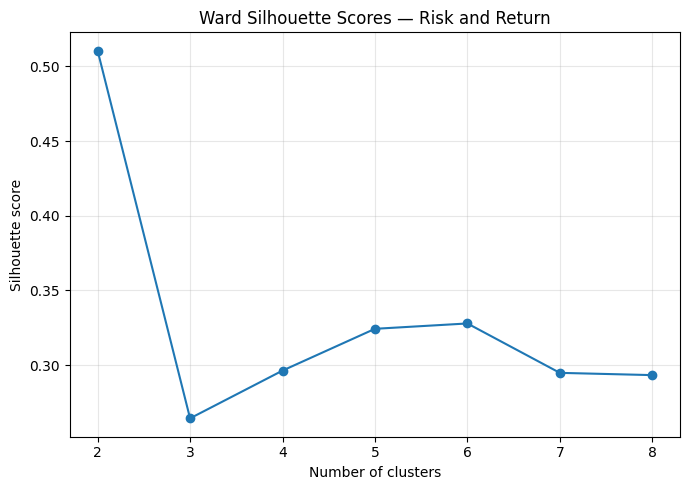

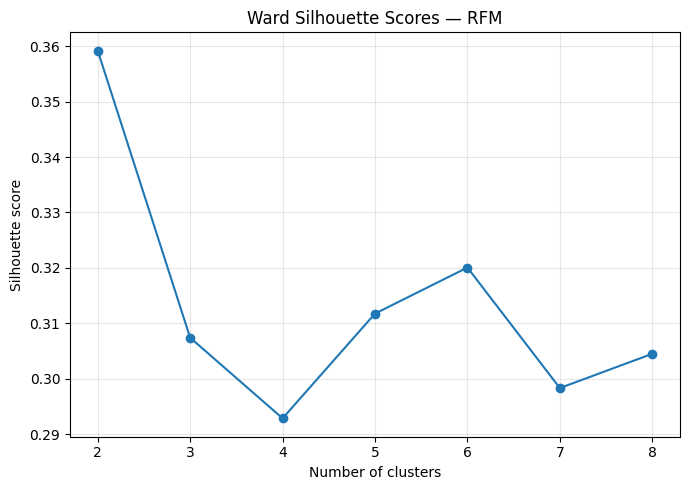

Risk and Return cluster sizes:
RR_Ward
0    155
1     36
2    123
3    177
Name: count, dtype: int64

RFM cluster sizes:
RFM_Ward
0     92
1    209
2    147
3     43
Name: count, dtype: int64

Risk and Return cluster profiles:


,MeanWeeklyReturn,Beta
Cluster,,
0,0.001,1.202
1,0.009,1.519
2,0.002,0.524
3,0.004,0.995



RFM cluster profiles:


,Recency,Frequency,Monetary
Cluster,,,
0,55.587,2.054,4.569727e+10
1,11.139,2.943,1.111359e+10
2,12.701,2.959,8.393315e+10
3,16.837,5.372,1.496218e+10


In [ ]:
# Produce dendrograms
Z_rr = linkage(X_rr, method="ward", metric="euclidean")
Z_rfm = linkage(X_rfm, method="ward", metric="euclidean")

for Z, title, filename in [
    (Z_rr, "Risk and Return", "risk_return_dendrogram.png"),
    (Z_rfm, "Trading Activity (RFM)", "rfm_dendrogram.png")
]:
    plt.figure(figsize=(12, 6))
    dendrogram(Z, truncate_mode="lastp", p=30)
    plt.title(f"Ward Dendrogram — {title}")
    plt.xlabel("Cluster groups")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.savefig(f"{BASE}/figures/{filename}", dpi=300)
    plt.show()


# Compare cluster counts from 2 to 8
def ward_scan(X, name):
    results = []

    for k in range(2, 9):
        labels = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward",
            metric="euclidean"
        ).fit_predict(X)

        sizes = pd.Series(labels).value_counts().sort_index()

        results.append({
            "Clusters": k,
            "Silhouette Score": silhouette_score(X, labels),
            "Cluster Sizes": sizes.tolist()
        })

    result = pd.DataFrame(results)
    result["Feature Matrix"] = name
    return result


ward_rr = ward_scan(X_rr, "Risk and Return")
ward_rfm = ward_scan(X_rfm, "RFM")

display(ward_rr.round(3))
display(ward_rfm.round(3))


# Plot silhouette score comparisons
for result, name in [
    (ward_rr, "Risk and Return"),
    (ward_rfm, "RFM")
]:
    plt.figure(figsize=(7, 5))
    plt.plot(
        result["Clusters"],
        result["Silhouette Score"],
        marker="o"
    )
    plt.xticks(range(2, 9))
    plt.xlabel("Number of clusters")
    plt.ylabel("Silhouette score")
    plt.title(f"Ward Silhouette Scores — {name}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


k_rr_ward = 4
k_rfm_ward = 4

fv["RR_Ward"] = AgglomerativeClustering(
    n_clusters=k_rr_ward,
    linkage="ward",
    metric="euclidean"
).fit_predict(X_rr)

fv["RFM_Ward"] = AgglomerativeClustering(
    n_clusters=k_rfm_ward,
    linkage="ward",
    metric="euclidean"
).fit_predict(X_rfm)


# Display final cluster sizes
print("Risk and Return cluster sizes:")
print(fv["RR_Ward"].value_counts().sort_index())

print("\nRFM cluster sizes:")
print(fv["RFM_Ward"].value_counts().sort_index())


rr_profiles = rr.assign(
    Cluster=fv["RR_Ward"].values
).groupby("Cluster").mean()

rfm_profiles = rfm.assign(
    Cluster=fv["RFM_Ward"].values
).groupby("Cluster").mean()

print("\nRisk and Return cluster profiles:")
display(rr_profiles.round(3))

print("\nRFM cluster profiles:")
display(rfm_profiles.round(3))

**2.3 K means clustering**

,Clusters,Silhouette Score,Inertia,Cluster Sizes,Feature Matrix
0,2,0.389,627.141,"[345, 146]",Risk and Return
1,3,0.321,473.601,"[166, 121, 204]",Risk and Return
2,4,0.324,373.905,"[160, 37, 174, 120]",Risk and Return
3,5,0.338,313.621,"[54, 133, 129, 157, 18]",Risk and Return
4,6,0.333,261.097,"[54, 121, 43, 159, 7, 107]",Risk and Return
5,7,0.336,224.491,"[51, 71, 80, 7, 145, 67, 70]",Risk and Return
6,8,0.354,192.951,"[40, 77, 43, 138, 81, 29, 7, 76]",Risk and Return


,Clusters,Silhouette Score,Inertia,Cluster Sizes,Feature Matrix
0,2,0.424,1079.102,"[422, 69]",RFM
1,3,0.325,807.181,"[153, 275, 63]",RFM
2,4,0.341,616.031,"[215, 93, 61, 122]",RFM
3,5,0.358,520.538,"[122, 89, 68, 201, 11]",RFM
4,6,0.347,440.933,"[42, 105, 120, 11, 145, 68]",RFM
5,7,0.348,389.894,"[120, 68, 106, 42, 11, 143, 1]",RFM
6,8,0.328,346.603,"[106, 68, 11, 135, 83, 67, 20, 1]",RFM


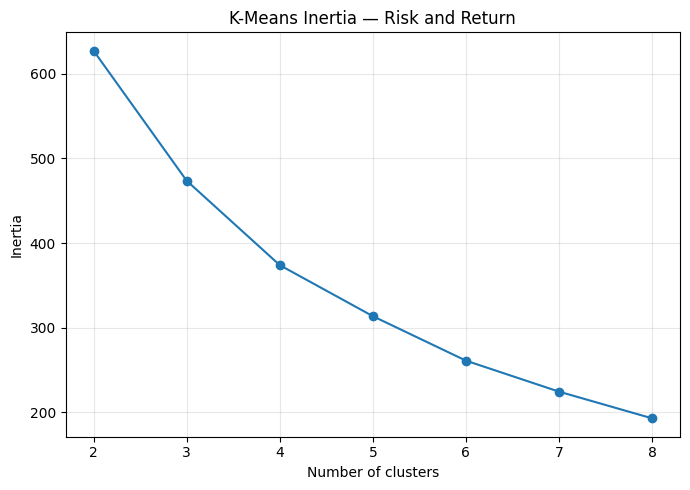

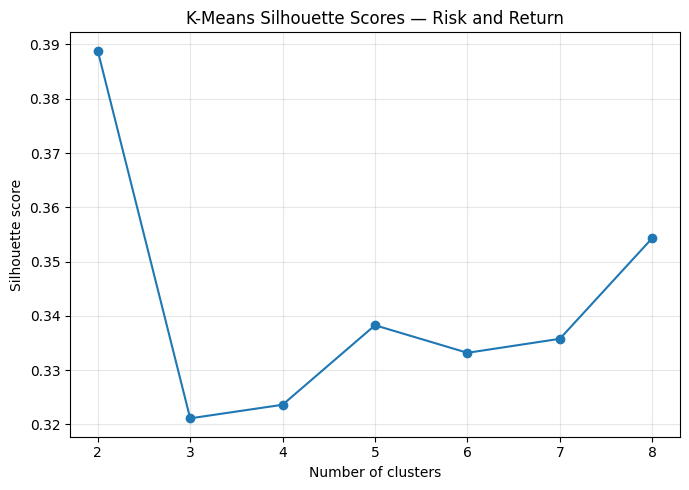

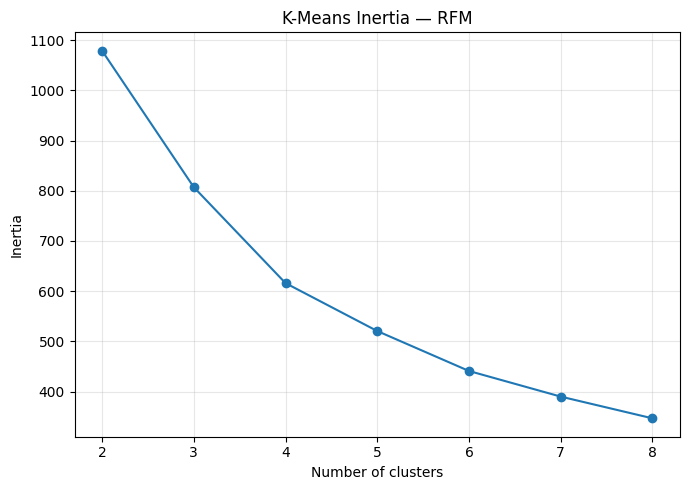

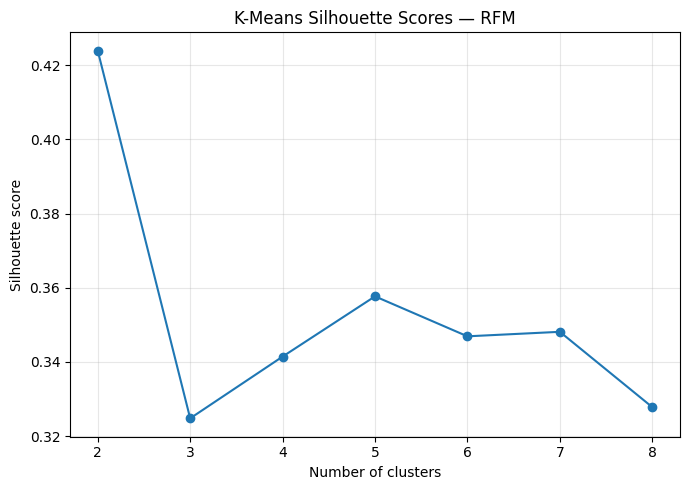

Risk and Return cluster sizes:
RR_KMeans
0    160
1     37
2    174
3    120
Name: count, dtype: int64

RFM cluster sizes:
RFM_KMeans
0    215
1     93
2     61
3    122
Name: count, dtype: int64


In [ ]:
# Test cluster counts from 2 to 8
def kmeans_scan(X, name):
    results = []

    for k in range(2, 9):
        model = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=42
        )

        labels = model.fit_predict(X)
        sizes = pd.Series(labels).value_counts().sort_index()

        results.append({
            "Clusters": k,
            "Silhouette Score": silhouette_score(X, labels),
            "Inertia": model.inertia_,
            "Cluster Sizes": sizes.tolist()
        })

    result = pd.DataFrame(results)
    result["Feature Matrix"] = name

    return result


km_rr = kmeans_scan(X_rr, "Risk and Return")
km_rfm = kmeans_scan(X_rfm, "RFM")

display(km_rr.round(3))
display(km_rfm.round(3))


# Plot inertia and silhouette scores
for result, name in [
    (km_rr, "Risk and Return"),
    (km_rfm, "RFM")
]:

    # Inertia plot
    plt.figure(figsize=(7, 5))
    plt.plot(result["Clusters"], result["Inertia"], marker="o")
    plt.xticks(range(2, 9))
    plt.title(f"K-Means Inertia — {name}")
    plt.xlabel("Number of clusters")
    plt.ylabel("Inertia")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Silhouette plot
    plt.figure(figsize=(7, 5))
    plt.plot(result["Clusters"], result["Silhouette Score"], marker="o")
    plt.xticks(range(2, 9))
    plt.title(f"K-Means Silhouette Scores — {name}")
    plt.xlabel("Number of clusters")
    plt.ylabel("Silhouette score")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# Select final cluster counts after reviewing the results
k_rr_km = 4
k_rfm_km = 4


# Fit final K-Means models
km_rr_final = KMeans(
    n_clusters=k_rr_km,
    n_init=20,
    random_state=42
)

km_rfm_final = KMeans(
    n_clusters=k_rfm_km,
    n_init=20,
    random_state=42
)

fv["RR_KMeans"] = km_rr_final.fit_predict(X_rr)
fv["RFM_KMeans"] = km_rfm_final.fit_predict(X_rfm)


# Display final cluster sizes
print("Risk and Return cluster sizes:")
print(fv["RR_KMeans"].value_counts().sort_index())

print("\nRFM cluster sizes:")
print(fv["RFM_KMeans"].value_counts().sort_index())


# Save results
fv.to_csv(
    f"{BASE}/outputs/2_3_kmeans_selected_clusters.csv",
    index=False
)

**2.4 Cluster profiles and algorithm comparison**

Risk and Return — Ward


,MeanWeeklyReturn,Beta,Share_Count
Cluster,,,
0,0.001,1.202,155
1,0.009,1.519,36
2,0.002,0.524,123
3,0.004,0.995,177


Risk and Return — K-Means


,MeanWeeklyReturn,Beta,Share_Count
Cluster,,,
0,0.005,0.997,160
1,0.008,1.781,37
2,0.002,0.612,174
3,0.001,1.247,120


RFM — Ward


,Recency,Frequency,Monetary,Share_Count
Cluster,,,,
0,55.587,2.054,4.569727e+10,92
1,11.139,2.943,1.111359e+10,209
2,12.701,2.959,8.393315e+10,147
3,16.837,5.372,1.496218e+10,43


RFM — K-Means


,Recency,Frequency,Monetary,Share_Count
Cluster,,,,
0,13.279,2.372,1.516509e+10,215
1,15.591,3.258,1.181621e+11,93
2,66.016,1.672,5.618009e+10,61
3,13.943,4.549,1.501539e+10,122


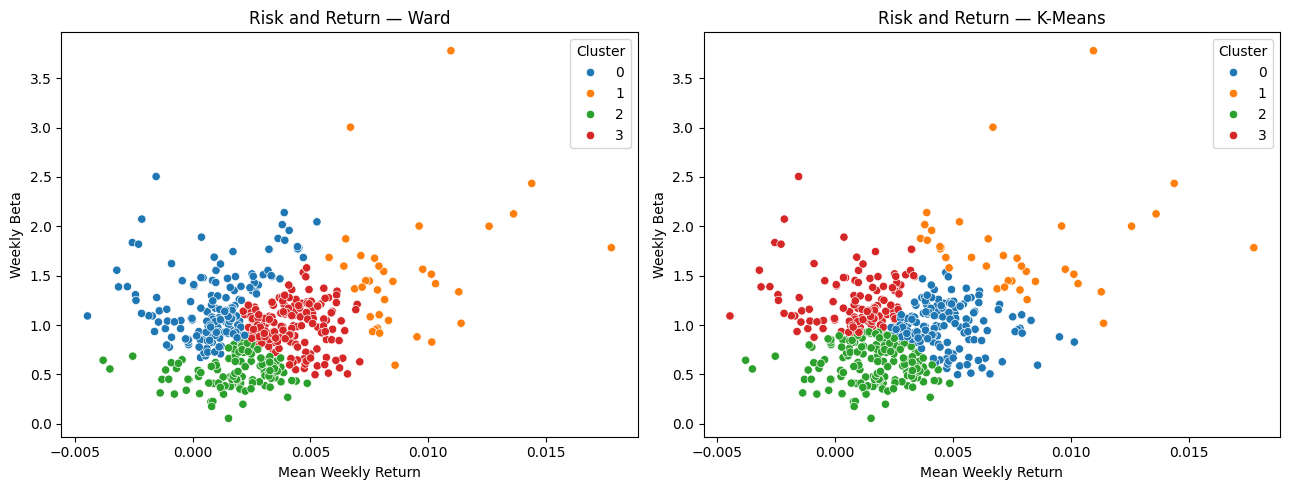

Variance explained by PC1 and PC2: 0.795


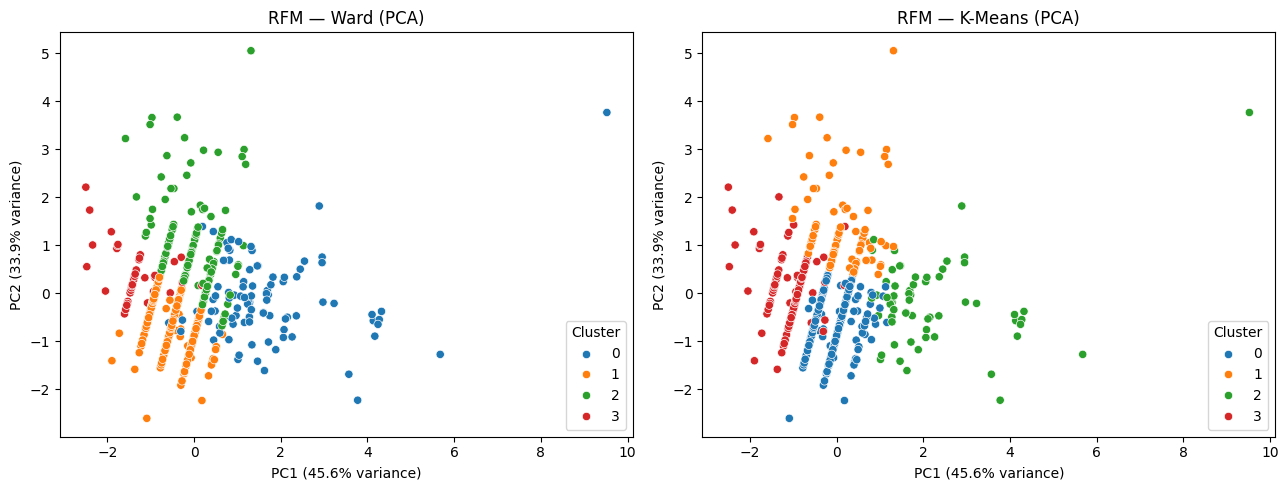

Risk and Return ARI: 0.595
RFM ARI: 0.353


In [ ]:
# Create cluster profiles using original feature values

def cluster_profile(features, ward_col, km_col):
    ward = fv.groupby(ward_col)[features].mean()
    ward["Share_Count"] = fv.groupby(ward_col).size()
    ward.index.name = "Cluster"

    kmeans = fv.groupby(km_col)[features].mean()
    kmeans["Share_Count"] = fv.groupby(km_col).size()
    kmeans.index.name = "Cluster"

    return ward.round(3), kmeans.round(3)


# Risk and Return profiles
rr_ward_profile, rr_kmeans_profile = cluster_profile(
    ["MeanWeeklyReturn", "Beta"],
    "RR_Ward",
    "RR_KMeans"
)

print("Risk and Return — Ward")
display(rr_ward_profile)

print("Risk and Return — K-Means")
display(rr_kmeans_profile)


# RFM profiles using original Monetary values
rfm_ward_profile, rfm_kmeans_profile = cluster_profile(
    ["Recency", "Frequency", "Monetary"],
    "RFM_Ward",
    "RFM_KMeans"
)

print("RFM — Ward")
display(rfm_ward_profile)

print("RFM — K-Means")
display(rfm_kmeans_profile)


# Risk and Return: labelled 2D scatter plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, cluster_col, algorithm in [
    (axes[0], "RR_Ward", "Ward"),
    (axes[1], "RR_KMeans", "K-Means")
]:
    sns.scatterplot(
        data=fv,
        x="MeanWeeklyReturn",
        y="Beta",
        hue=cluster_col,
        palette="tab10",
        ax=ax
    )
    ax.set_title(f"Risk and Return — {algorithm}")
    ax.set_xlabel("Mean Weekly Return")
    ax.set_ylabel("Weekly Beta")
    ax.legend(title="Cluster")

plt.tight_layout()
plt.show()


# RFM: Reduce three features into two dimensions using PCA
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(X_rfm)

pca_df = pd.DataFrame(
    rfm_pca,
    columns=["PC1", "PC2"],
    index=fv.index
)

pca_df["Ward"] = fv["RFM_Ward"]
pca_df["KMeans"] = fv["RFM_KMeans"]

variance = pca.explained_variance_ratio_

print("Variance explained by PC1 and PC2:",
      round(variance.sum(), 3))


# Plot both algorithms
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, cluster_col, algorithm in [
    (axes[0], "Ward", "Ward"),
    (axes[1], "KMeans", "K-Means")
]:
    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue=cluster_col,
        palette="tab10",
        ax=ax
    )
    ax.set_title(f"RFM — {algorithm} (PCA)")
    ax.set_xlabel(f"PC1 ({variance[0]:.1%} variance)")
    ax.set_ylabel(f"PC2 ({variance[1]:.1%} variance)")
    ax.legend(title="Cluster")

plt.tight_layout()
plt.show()


# Compare how similarly both algorithms group the same shares

print("Risk and Return ARI:",
      round(adjusted_rand_score(
          fv["RR_Ward"], fv["RR_KMeans"]
      ), 3))

print("RFM ARI:",
      round(adjusted_rand_score(
          fv["RFM_Ward"], fv["RFM_KMeans"]
      ), 3))


**2.5 RFM sensitivity and correlated inputs**

**2.5.1 Correlation analysis**

Pearson Correlation:


,Recency,Frequency,log1p(Monetary)
Recency,1.000,-0.342,0.159
Frequency,-0.342,1.000,0.022
log1p(Monetary),0.159,0.022,1.000


Spearman Correlation:


,Recency,Frequency,log1p(Monetary)
Recency,1.000,-0.189,0.147
Frequency,-0.189,1.000,-0.039
log1p(Monetary),0.147,-0.039,1.000


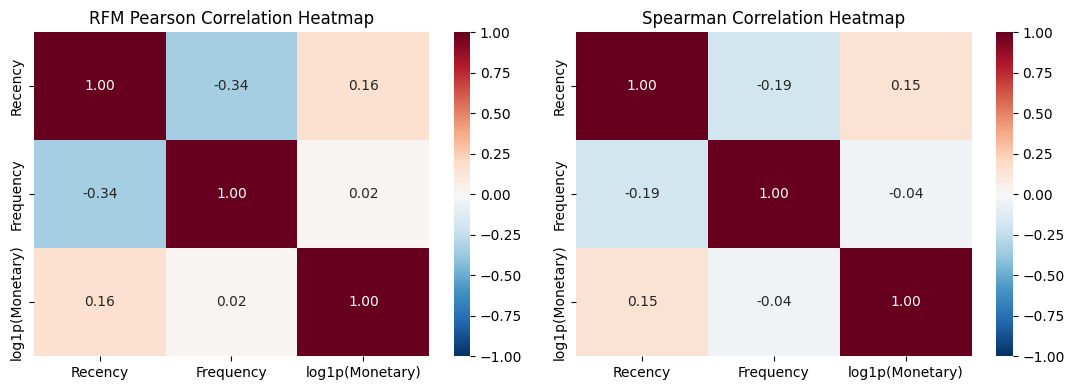

In [ ]:
corr_in = fv[["Recency", "Frequency", "Monetary"]].copy()
corr_in["log1p(Monetary)"] = np.log1p(corr_in["Monetary"])
corr_in = corr_in.drop(columns="Monetary")

# Pearson and Spearman correlation matrices
pearson = corr_in.corr(method="pearson")
spearman = corr_in.corr(method="spearman")

print("Pearson Correlation:")
display(pearson.round(3))

print("Spearman Correlation:")
display(spearman.round(3))

# Correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, matrix, title in [
    (axes[0], pearson, "RFM Pearson Correlation Heatmap"),
    (axes[1], spearman, "Spearman Correlation Heatmap")
]:
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        ax=ax
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()


**2.5.2 Removal of Monetary**

Adjusted Rand Index: 0.234


Reduced R-F,0,1,2,3
Original RFM,,,,
0,3,79,0,10
1,143,0,66,0
2,87,1,59,0
3,42,1,0,0


,mean,median,count,Solution
Cluster,,,,
0,4.569727e+10,2.048974e+10,92,Original RFM
1,1.111359e+10,1.078591e+10,209,Original RFM
2,8.393315e+10,4.119174e+10,147,Original RFM
3,1.496218e+10,1.442997e+10,43,Original RFM
0,3.941630e+10,1.478438e+10,275,Reduced R-F
1,2.937402e+10,2.013167e+10,81,Reduced R-F
2,3.433790e+10,1.769899e+10,125,Reduced R-F
3,1.997420e+11,2.378595e+10,10,Reduced R-F


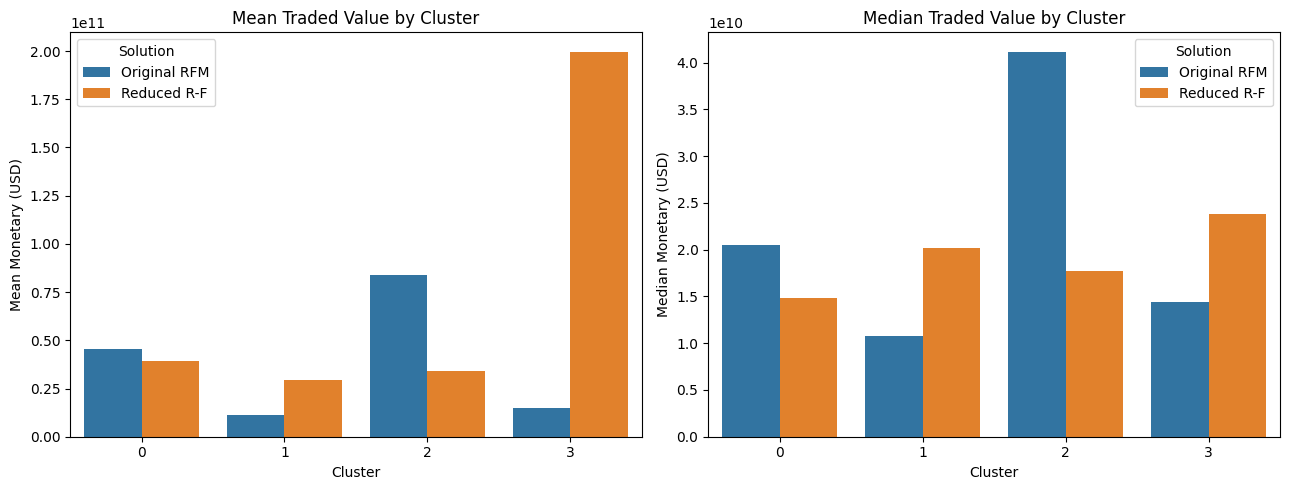

In [ ]:
# Create R-F matrix and standardise it again
rf_only = fv[["Recency", "Frequency"]]

scaler_rf = StandardScaler()
X_rf = scaler_rf.fit_transform(rf_only)


# Repeat Ward clustering using the same cluster count
fv["RF_Ward"] = AgglomerativeClustering(
    n_clusters=k_rfm_ward,
    linkage="ward",
    metric="euclidean"
).fit_predict(X_rf)


# Compare original RFM and reduced R-F memberships using ARI
ari = adjusted_rand_score(
    fv["RFM_Ward"],
    fv["RF_Ward"]
)

print("Adjusted Rand Index:", round(ari, 3))


# Display membership comparison
membership_table = pd.crosstab(
    fv["RFM_Ward"],
    fv["RF_Ward"],
    rownames=["Original RFM"],
    colnames=["Reduced R-F"]
)

display(membership_table)


# Compare original Monetary values across both solutions
monetary_comparison = pd.concat([
    fv.groupby("RFM_Ward")["Monetary"]
      .agg(["mean", "median", "count"])
      .assign(Solution="Original RFM")
      .rename_axis("Cluster"),

    fv.groupby("RF_Ward")["Monetary"]
      .agg(["mean", "median", "count"])
      .assign(Solution="Reduced R-F")
      .rename_axis("Cluster")
])

display(monetary_comparison.round(2))

# Traded value profile comparison chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=monetary_comparison,
    x="Cluster",
    y="mean",
    hue="Solution",
    ax=axes[0]
)
axes[0].set_title("Mean Traded Value by Cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Mean Monetary (USD)")

sns.barplot(
    data=monetary_comparison,
    x="Cluster",
    y="median",
    hue="Solution",
    ax=axes[1]
)
axes[1].set_title("Median Traded Value by Cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Median Monetary (USD)")

plt.tight_layout()
plt.savefig(f"{BASE}/figures/2_5_traded_value_profile_comparison.png", dpi=300)
plt.show()

# **Task 3 Business Intelligence and Critical Review**

**3.2 Review of results and visualisation**

**3.2.1 Cluster profiles and sector composition**

Risk-Return Ward profiles:


Share_Count MeanWeeklyReturn            Beta        
                                mean  median    mean  median
RR_Ward                                                     
0               155           0.0009  0.0010  1.2016  1.0948
1                36           0.0090  0.0080  1.5189  1.4445
2               123           0.0018  0.0020  0.5240  0.5187
3               177           0.0041  0.0041  0.9952  0.9994

RFM Ward profiles:


Share_Count Recency        Frequency             Monetary  \
                        mean median      mean median          mean   
RFM_Ward                                                             
0                 92   55.59   53.0      2.05    2.0  4.569727e+10   
1                209   11.14   11.0      2.94    3.0  1.111359e+10   
2                147   12.70   11.0      2.96    3.0  8.393315e+10   
3                 43   16.84   11.0      5.37    5.0  1.496218e+10   

                        
                median  
RFM_Ward                
0         2.048974e+10  
1         1.078591e+10  
2         4.119174e+10  
3         1.442997e+10

Risk-Return sector composition (%):


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RR_Ward,,,,,,,,,,,
0,2.6,12.9,3.2,0.0,10.3,15.5,16.8,21.9,7.7,7.1,1.9
1,2.8,11.1,0.0,11.1,13.9,2.8,19.4,30.6,2.8,2.8,2.8
2,5.7,2.4,20.3,0.8,11.4,19.5,8.9,1.6,3.3,5.7,20.3
3,5.1,11.3,1.1,9.0,22.6,5.1,19.8,15.3,4.0,6.2,0.6


RFM sector composition (%):


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RFM_Ward,,,,,,,,,,,
0,4.3,10.9,8.7,2.2,14.1,9.8,9.8,21.7,8.7,0.0,9.8
1,2.4,6.7,5.7,3.8,17.2,9.1,19.1,9.1,6.2,12.0,8.6
2,6.8,12.9,6.8,6.8,15.6,14.3,12.9,19.7,1.4,2.0,0.7
3,4.7,9.3,4.7,2.3,7.0,20.9,25.6,14.0,2.3,4.7,4.7


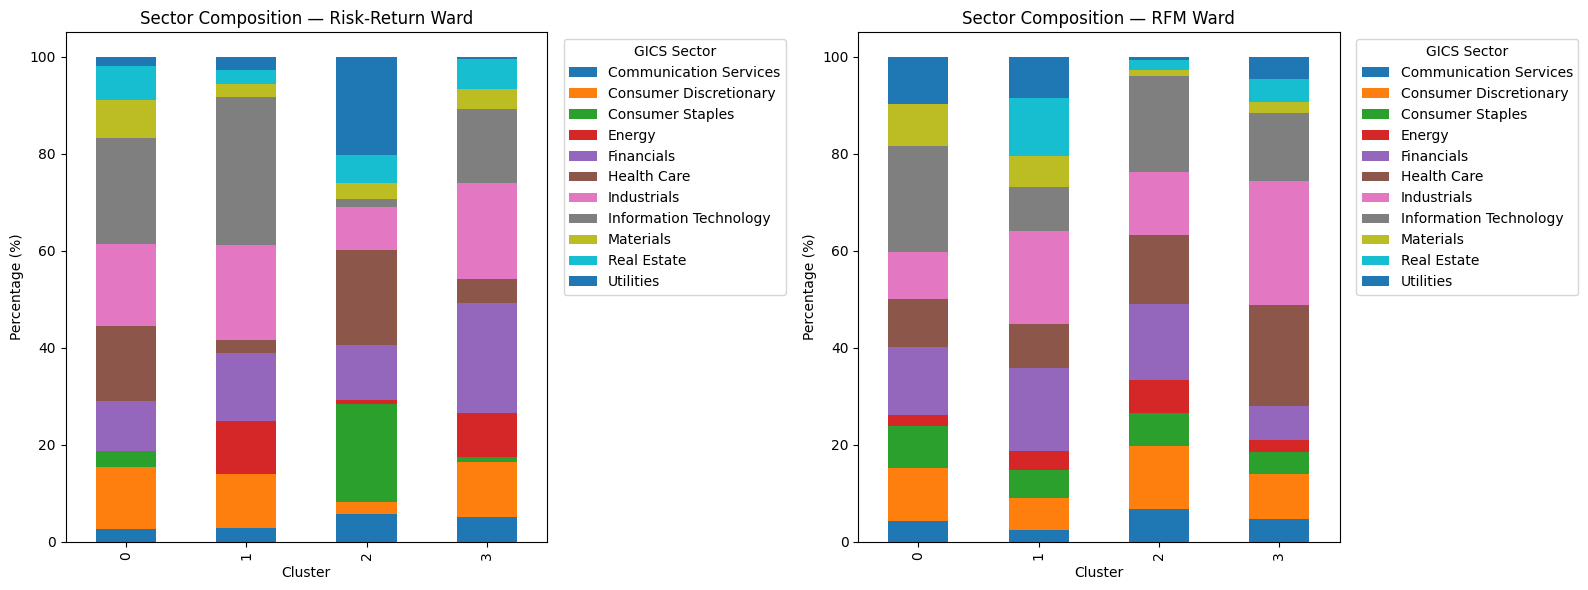

In [ ]:
# Original-unit cluster profiles

rr_metrics = ["MeanWeeklyReturn", "Beta"]
rfm_metrics = ["Recency", "Frequency", "Monetary"]

def cluster_profile(cluster, metrics):
    profile = fv.groupby(cluster)[metrics].agg(["mean", "median"])
    profile.insert(0, "Share_Count", fv[cluster].value_counts().sort_index())
    return profile

rr_profile = cluster_profile("RR_Ward", rr_metrics)
rfm_profile = cluster_profile("RFM_Ward", rfm_metrics)

print("Risk-Return Ward profiles:")
display(rr_profile.round(4))

print("RFM Ward profiles:")
display(rfm_profile.round(2))


# Sector composition within each cluster (%)

rr_sector_mix = pd.crosstab(
    fv["RR_Ward"], fv["GICS Sector"], normalize="index"
) * 100

rfm_sector_mix = pd.crosstab(
    fv["RFM_Ward"], fv["GICS Sector"], normalize="index"
) * 100

print("Risk-Return sector composition (%):")
display(rr_sector_mix.round(1))

print("RFM sector composition (%):")
display(rfm_sector_mix.round(1))


# Visualise sector composition

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

rr_sector_mix.plot(kind="bar", stacked=True, ax=axes[0])
axes[0].set_title("Sector Composition — Risk-Return Ward")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Percentage (%)")

rfm_sector_mix.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Sector Composition — RFM Ward")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Percentage (%)")

for ax in axes:
    ax.legend(title="GICS Sector", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.savefig(f"{BASE}/figures/3_2_1_sector_composition.png", dpi=300)
plt.show()
